# 01 · Exploratory Data Analysis (Phase 1)

**Goal:** understand the Ames training data well enough that every preprocessing choice in Phase 3 is deliberate.

**Rules**
- Only `data/processed/train.csv` (the 80% training split) is loaded. The test split is never opened.
- Every finding ends as a row in the decision log (Step 7, written to `docs/eda_decisions.md`).

| Step | Question | Output |
|---|---|---|
| 1 | What does the data look like? | Shape, dtypes, duplicates |
| 2 | What type is each column? | Column-type table |
| 3 | What does the target look like? | Log-transform decision |
| 4 | What is missing, and why? | Fill strategy per column |
| 5 | How do the features behave? | Skew, correlations, multicollinearity, categoricals |
| 6 | Are there outliers? | Outlier rule and rows |
| 7 | What did we decide? | `docs/eda_decisions.md` |

## Setup
Imports, paths from `config.py`, a figure-saving helper, and a collector for the decision log.

In [1]:
import datetime as dt
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

try:
    from house_price import config
except ImportError:  # package not installed: fall back to the src/ layout
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    from house_price import config

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

config.ensure_dirs()
REPORTS_DIR = config.PROJECT_ROOT / "reports"
DOCS_DIR = config.PROJECT_ROOT / "docs"
DOCS_DIR.mkdir(exist_ok=True)
print("Project root:", config.PROJECT_ROOT)


def save_fig(name: str) -> None:
    """Save the current matplotlib figure to reports/figures/<name>.png."""
    path = config.FIGURES_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(config.PROJECT_ROOT)}")


def is_num(series: pd.Series) -> bool:
    """True for numeric dtypes (works for object and the newer string dtypes)."""
    return pd.api.types.is_numeric_dtype(series)


DECISIONS = []  # every step appends here; Step 7 writes them to docs/eda_decisions.md


def log_decision(step: int, finding: str, decision: str, applied_in: str) -> None:
    DECISIONS.append(
        {"step": step, "finding": finding, "decision": decision, "applied_in": applied_in}
    )

Project root: C:\Users\ASUS\OneDrive\Desktop\ML Projects\House_Price_Prediction


## Step 1 · Load the training data
Load only the training split, then check shape, dtypes, `head()` and duplicate rows.

**Output:** rows x columns, and confirmation that `SalePrice` is present and no test data is loaded.

In [2]:
TRAIN_PATH = config.PROCESSED_DIR / "train.csv"
if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        "data/processed/train.csv not found. Put Kaggle's train.csv in data/raw/ and run "
        "`make data` (see data/README.md)."
    )

LOADED_FILES = [TRAIN_PATH.name]  # audit trail: the test split must never appear here
df = pd.read_csv(TRAIN_PATH)
df = df.drop(columns=[config.ID_COLUMN], errors="ignore")

assert config.TARGET in df.columns, f"{config.TARGET} missing from the training data"
print(f"Loaded {TRAIN_PATH.name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Target: {config.TARGET} | missing target values: {df[config.TARGET].isna().sum()}")
print(f"Files loaded in this notebook: {LOADED_FILES}")

Loaded train.csv: 1,168 rows x 80 columns
Target: SalePrice | missing target values: 0
Files loaded in this notebook: ['train.csv']


In [3]:
df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,20,RL,70.0,8400,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1957,1957,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,Gd,CBlock,TA,TA,No,Rec,922,Unf,0,392,1314,GasA,TA,Y,SBrkr,1314,0,0,1314,1,0,1,0,3,1,TA,5,Typ,0,NaN,Attchd,1957.0,RFn,1,294,TA,TA,Y,250,0,0,0,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal,145000
1,60,RL,59.0,7837,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,7,1993,1994,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,Gd,TA,PConc,Gd,TA,No,Unf,0,Unf,0,799,799,GasA,Gd,Y,SBrkr,799,772,0,1571,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1993.0,RFn,2,380,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,5,2009,WD,Normal,178000
2,30,RL,67.0,8777,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Feedr,Norm,1Fam,1Story,5,7,1910,1950,Gable,CompShg,MetalSd,Wd Sdng,NaN,0.0,TA,TA,CBlock,Fa,TA,No,Unf,0,Unf,0,796,796,GasA,Gd,Y,FuseA,796,0,0,796,0,0,1,0,2,1,TA,4,Typ,0,NaN,NaN,NaN,NaN,0,0,NaN,NaN,P,328,0,164,0,0,0,NaN,MnPrv,NaN,0,5,2008,WD,Normal,85000
3,50,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,SWISU,Feedr,Norm,1Fam,1.5Fin,5,7,1937,1950,Gable,CompShg,Wd Sdng,Wd Sdng,BrkFace,252.0,TA,TA,BrkTil,Gd,TA,No,ALQ,569,Unf,0,162,731,GasA,Ex,Y,SBrkr,981,787,0,1768,1,0,1,1,3,1,Gd,7,Typ,2,TA,Detchd,1939.0,Unf,1,240,TA,TA,Y,0,0,264,0,0,0,NaN,MnPrv,NaN,0,6,2007,WD,Normal,175000
4,50,RL,50.0,5000,Pave,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Norm,Norm,1Fam,1.5Fin,5,6,1924,1950,Gable,CompShg,BrkFace,Wd Sdng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,LwQ,218,Unf,0,808,1026,GasA,TA,Y,SBrkr,1026,665,0,1691,0,0,2,0,3,1,Gd,6,Typ,1,Gd,Detchd,1924.0,Unf,1,308,TA,TA,Y,0,0,242,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,127000


In [4]:
print("Column dtypes:")
print(df.dtypes.astype(str).value_counts().to_string())

n_dupes = int(df.duplicated().sum())
print(f"\nDuplicate rows: {n_dupes}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")

log_decision(
    1,
    f"{df.shape[0]:,} training rows x {df.shape[1] - 1} features; {n_dupes} duplicate rows",
    "No duplicate handling needed" if n_dupes == 0 else "Drop duplicate rows in training data",
    "Phase 3 data cleaning",
)

Column dtypes:
str        43
int64      34
float64     3

Duplicate rows: 0
Memory usage: 2.87 MB


## Step 2 · Understand the columns
Read `data_description.txt` next to the dtypes, then group every feature as **numeric**, **nominal** (unordered category) or **ordinal** (ordered category).

Traps to handle:
- `MSSubClass` and `MoSold` are stored as numbers but are categories.
- `OverallQual`, `OverallCond` and the quality columns (`ExterQual`, `KitchenQual`, ...) have an inherent order.

**Output:** a column-type table that Phase 3 uses to build the `ColumnTransformer`.

In [5]:
desc_path = config.RAW_DIR / "data_description.txt"
if desc_path.exists():
    print(desc_path.read_text(errors="ignore")[:3000])
    print("\n... (open the file to read the rest)")
else:
    print("data_description.txt not found in data/raw/ - download it from the Kaggle page; "
          "it defines every column and what 'NA' means for each.")

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [6]:
ORDINAL_CANDIDATES = [
    "OverallQual", "OverallCond", "ExterQual", "ExterCond", "BsmtQual", "BsmtCond",
    "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "HeatingQC", "KitchenQual",
    "FireplaceQu", "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence",
    "LotShape", "LandSlope", "Utilities", "Functional", "PavedDrive",
]
NOMINAL_CODED_AS_NUMBERS = ["MSSubClass", "MoSold"]

features = df.drop(columns=[config.TARGET])
ordinal_cols = [c for c in ORDINAL_CANDIDATES if c in features.columns]
nominal_forced = [c for c in NOMINAL_CODED_AS_NUMBERS if c in features.columns]
nominal_cols = [
    c for c in features.columns
    if c not in ordinal_cols and (not is_num(features[c]) or c in nominal_forced)
]
numeric_cols = [c for c in features.columns if c not in ordinal_cols and c not in nominal_cols]

rows = []
for c in features.columns:
    if c in ordinal_cols:
        kind = "ordinal"
    elif c in nominal_cols:
        kind = "nominal"
    else:
        kind = "numeric_discrete" if features[c].nunique() <= 15 else "numeric_continuous"
    rows.append(
        {
            "column": c,
            "kind": kind,
            "dtype": str(features[c].dtype),
            "n_unique": features[c].nunique(),
            "n_missing": int(features[c].isna().sum()),
        }
    )
col_types = pd.DataFrame(rows)
col_types.to_csv(REPORTS_DIR / "column_types.csv", index=False)

print(col_types["kind"].value_counts().to_string())
print("\nSaved -> reports/column_types.csv")
col_types

kind
nominal               25
ordinal               22
numeric_continuous    21
numeric_discrete      11

Saved -> reports/column_types.csv


,column,kind,dtype,n_unique,n_missing
0,MSSubClass,nominal,int64,15,0
1,MSZoning,nominal,str,5,0
2,LotFrontage,numeric_continuous,float64,107,217
3,LotArea,numeric_continuous,int64,890,0
4,Street,nominal,str,2,0
5,Alley,nominal,str,2,1094
6,LotShape,ordinal,str,4,0
7,LandContour,nominal,str,4,0
8,Utilities,ordinal,str,2,0
9,LotConfig,nominal,str,5,0


In [7]:
log_decision(
    2,
    f"{len(nominal_forced)} numerically-coded categories ({', '.join(nominal_forced)}); "
    f"{len(ordinal_cols)} ordered columns (quality/condition ratings etc.)",
    "Cast MSSubClass and MoSold to category; ordinal-encode ordered columns "
    "(e.g. Po<Fa<TA<Gd<Ex); one-hot encode nominal columns with handle_unknown='ignore'",
    "Phase 3 ColumnTransformer",
)

## Step 3 · Analyze the target (`SalePrice`)
Histogram + KDE, skewness, then the same after `log1p`.

**Output:** the decision "model `log1p(SalePrice)`", with before/after plots saved.

In [8]:
y = df[config.TARGET]
y_log = np.log1p(y)

summary = pd.DataFrame({"SalePrice": y.describe(), "log1p(SalePrice)": y_log.describe()})
print(summary.round(3).to_string())

skew_raw, skew_log = y.skew(), y_log.skew()
kurt_raw, kurt_log = y.kurt(), y_log.kurt()
print(f"\nSkewness : raw = {skew_raw:.3f} | log1p = {skew_log:.3f}")
print(f"Kurtosis : raw = {kurt_raw:.3f} | log1p = {kurt_log:.3f}")

        SalePrice  log1p(SalePrice)
count    1168.000          1168.000
mean   181441.542            12.031
std     77263.584             0.391
min     34900.000            10.460
25%    130000.000            11.775
50%    165000.000            12.014
75%    214925.000            12.278
max    745000.000            13.521

Skewness : raw = 1.743 | log1p = 0.125
Kurtosis : raw = 5.475 | log1p = 0.700


Saved figure -> reports\figures\01_target_distribution.png


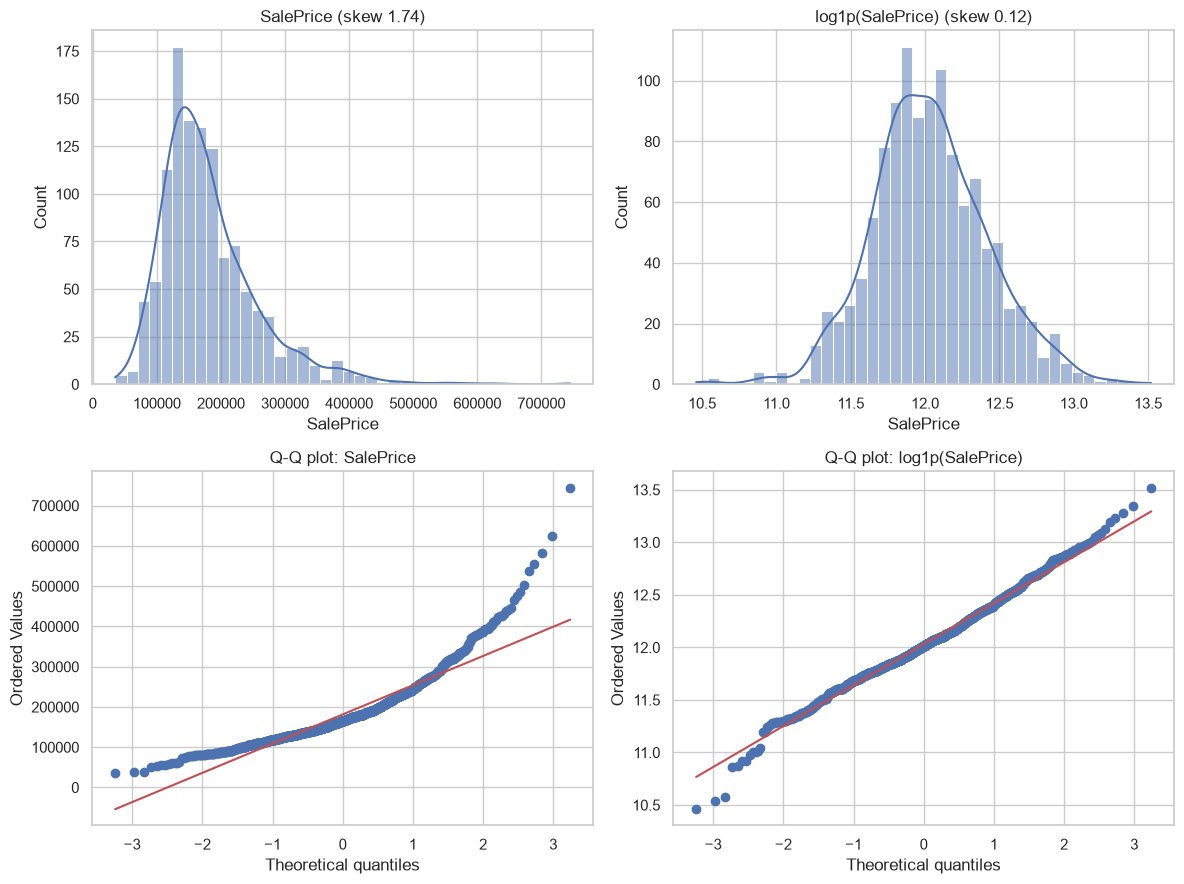

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(y, kde=True, bins=40, ax=axes[0, 0])
axes[0, 0].set_title(f"SalePrice (skew {skew_raw:.2f})")

sns.histplot(y_log, kde=True, bins=40, ax=axes[0, 1])
axes[0, 1].set_title(f"log1p(SalePrice) (skew {skew_log:.2f})")

stats.probplot(y, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q plot: SalePrice")

stats.probplot(y_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot: log1p(SalePrice)")

plt.tight_layout()
save_fig("01_target_distribution")
plt.show()

In [10]:
log_decision(
    3,
    f"SalePrice is right-skewed (skew {skew_raw:.2f}); after log1p skew is {skew_log:.2f} "
    "and the Q-Q plot is much closer to a straight line",
    "Train on log1p(SalePrice) and invert with expm1 for predictions; "
    "report RMSE on the log scale plus MAE and R2 on the price scale",
    "Phase 3 pipeline (TransformedTargetRegressor) and Phase 5 evaluation",
)

## Step 4 · Analyze missing values
Count and percentage per column, then separate:
- **Not applicable:** `NA` means the feature does not exist (no pool, no garage). Fill with a `"None"` category or 0.
- **Genuinely missing:** the value exists but was not recorded (e.g. `LotFrontage`). Impute.

**Output:** a missing-value table with a fill strategy per column.

In [11]:
feature_df = df.drop(columns=[config.TARGET])
missing = feature_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

miss_df = pd.DataFrame(
    {
        "missing": missing,
        "pct_missing": (missing / len(df) * 100).round(2),
        "dtype": feature_df[missing.index].dtypes.astype(str),
    }
)
print(f"{len(miss_df)} of {feature_df.shape[1]} feature columns have missing values")
miss_df

19 of 79 feature columns have missing values


,missing,pct_missing,dtype
PoolQC,1162,99.49,str
MiscFeature,1122,96.06,str
Alley,1094,93.66,str
Fence,935,80.05,str
MasVnrType,683,58.48,str
FireplaceQu,547,46.83,str
LotFrontage,217,18.58,float64
GarageType,64,5.48,str
GarageYrBlt,64,5.48,float64
GarageFinish,64,5.48,str


Saved figure -> reports\figures\02_missing_values.png


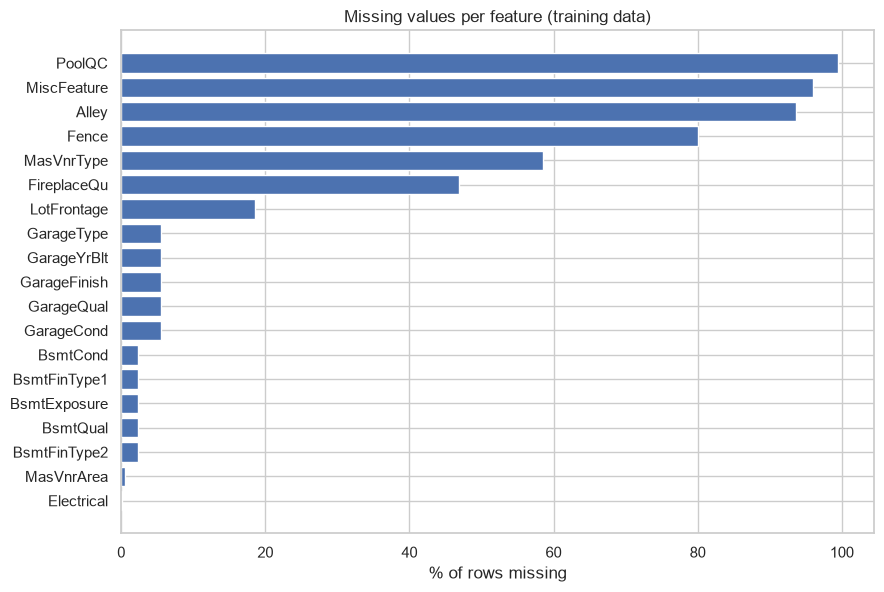

In [12]:
fig, ax = plt.subplots(figsize=(9, max(3, 0.32 * len(miss_df))))
ax.barh(miss_df.index[::-1], miss_df["pct_missing"].iloc[::-1])
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per feature (training data)")
plt.tight_layout()
save_fig("02_missing_values")
plt.show()

### Is `NA` really "feature absent"?
Test the hypothesis directly: if `PoolQC` is `NA` exactly when `PoolArea == 0`, then `NA` means "no pool", not "unknown".
A share near 1.0 supports "not applicable"; the few mismatches are the genuinely missing cases.

In [13]:
def has(*cols):
    return all(c in df.columns for c in cols)


def share_equal(mask_a, mask_b):
    return round(float((mask_a == mask_b).mean()), 3)


hypotheses = []
if has("PoolQC", "PoolArea"):
    hypotheses.append(("PoolQC is NA  <=>  PoolArea == 0",
                       share_equal(df["PoolQC"].isna(), df["PoolArea"] == 0)))
if has("FireplaceQu", "Fireplaces"):
    hypotheses.append(("FireplaceQu is NA  <=>  Fireplaces == 0",
                       share_equal(df["FireplaceQu"].isna(), df["Fireplaces"] == 0)))
if has("GarageType", "GarageArea"):
    hypotheses.append(("GarageType is NA  <=>  GarageArea == 0",
                       share_equal(df["GarageType"].isna(), df["GarageArea"] == 0)))
if has("GarageYrBlt", "GarageType"):
    hypotheses.append(("GarageYrBlt is NA  <=>  GarageType is NA",
                       share_equal(df["GarageYrBlt"].isna(), df["GarageType"].isna())))
if has("BsmtQual", "TotalBsmtSF"):
    hypotheses.append(("BsmtQual is NA  <=>  TotalBsmtSF == 0",
                       share_equal(df["BsmtQual"].isna(), df["TotalBsmtSF"] == 0)))
if has("MasVnrType", "MasVnrArea"):
    hypotheses.append(("MasVnrType is NA  <=>  MasVnrArea is NA",
                       share_equal(df["MasVnrType"].isna(), df["MasVnrArea"].isna())))

na_checks = pd.DataFrame(hypotheses, columns=["hypothesis", "share_of_rows_consistent"])
na_checks

,hypothesis,share_of_rows_consistent
0,PoolQC is NA <=> PoolArea == 0,1.00
1,FireplaceQu is NA <=> Fireplaces == 0,1.00
2,GarageType is NA <=> GarageArea == 0,1.00
3,GarageYrBlt is NA <=> GarageType is NA,1.00
4,BsmtQual is NA <=> TotalBsmtSF == 0,1.00
5,MasVnrType is NA <=> MasVnrArea is NA,0.42


In [14]:
NA_MEANS_NONE = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]


def strategy(col: str):
    """Return (why it is missing, how to fill it) for a column with missing values."""
    if col in NA_MEANS_NONE:
        return "not applicable (feature absent)", "Fill with 'None' category"
    if col == "MasVnrType":
        return "not applicable (no veneer)", "Fill with 'None' category"
    if col == "MasVnrArea":
        return "not applicable (no veneer)", "Fill with 0"
    if col == "GarageYrBlt":
        return ("not applicable (no garage)",
                "Fill with YearBuilt; consider dropping since it tracks YearBuilt")
    if col == "LotFrontage":
        return "genuinely missing", "Median imputation grouped by Neighborhood"
    if col == "Electrical":
        return "genuinely missing", "Mode imputation"
    fallback = "Median imputation" if is_num(df[col]) else "Mode imputation"
    return "REVIEW (not classified)", fallback


strategy_df = miss_df.join(
    pd.DataFrame(
        [strategy(c) for c in miss_df.index],
        index=miss_df.index,
        columns=["why_missing", "fill_strategy"],
    )
)
strategy_df.to_csv(REPORTS_DIR / "missing_value_strategy.csv")
print("Saved -> reports/missing_value_strategy.csv")
strategy_df

Saved -> reports/missing_value_strategy.csv


,missing,pct_missing,dtype,why_missing,fill_strategy
PoolQC,1162,99.49,str,not applicable (feature absent),Fill with 'None' category
MiscFeature,1122,96.06,str,not applicable (feature absent),Fill with 'None' category
Alley,1094,93.66,str,not applicable (feature absent),Fill with 'None' category
Fence,935,80.05,str,not applicable (feature absent),Fill with 'None' category
MasVnrType,683,58.48,str,not applicable (no veneer),Fill with 'None' category
FireplaceQu,547,46.83,str,not applicable (feature absent),Fill with 'None' category
LotFrontage,217,18.58,float64,genuinely missing,Median imputation grouped by Neighborhood
GarageType,64,5.48,str,not applicable (feature absent),Fill with 'None' category
GarageYrBlt,64,5.48,float64,not applicable (no garage),Fill with YearBuilt; consider dropping since i...
GarageFinish,64,5.48,str,not applicable (feature absent),Fill with 'None' category


In [15]:
unclassified = strategy_df.index[strategy_df["why_missing"].str.startswith("REVIEW")].tolist()
if unclassified:
    print("Columns still needing a manual look (check data_description.txt):", unclassified)

sparse_cols = strategy_df.index[strategy_df["pct_missing"] > 90].tolist()
none_cols = [c for c in strategy_df.index if c in NA_MEANS_NONE]
if len(na_checks):
    lo, hi = na_checks["share_of_rows_consistent"].min(), na_checks["share_of_rows_consistent"].max()
    consistency = f"NA matches the related size/count column in {lo:.1%} to {hi:.1%} of rows"
else:
    consistency = "consistency checks could not be run"

log_decision(
    4,
    f"{len(none_cols)} columns have NA meaning 'feature absent' (e.g. PoolQC, GarageType, BsmtQual); "
    f"{consistency}",
    "Fill these with the 'None' category (not the mode); fill MasVnrArea with 0",
    "Phase 3 imputers",
)
log_decision(
    4,
    "LotFrontage and Electrical are genuinely missing values",
    "LotFrontage: median by Neighborhood; Electrical: mode",
    "Phase 3 imputers (fit on training folds only)",
)
if sparse_cols:
    log_decision(
        4,
        f"Columns missing in more than 90% of rows: {', '.join(sparse_cols)}",
        "Replace with a binary Has_<feature> flag (or drop); compare both in Phase 4",
        "Phase 3 feature engineering",
    )
if unclassified:
    log_decision(
        4,
        f"Unclassified missing columns: {', '.join(unclassified)}",
        "Review manually against data_description.txt, then add to the strategy table",
        "Phase 3 imputers",
    )

## Step 5 · Analyze the features
**5a** Numeric distributions and skew · **5b** Correlation with the target · **5c** Multicollinearity · **5d** Categorical features.

### 5a · Numeric distributions and skewed columns

In [16]:
cont_cols = col_types.loc[col_types["kind"] == "numeric_continuous", "column"].tolist()
skew = df[cont_cols].skew().sort_values(ascending=False)
skew_df = pd.DataFrame({"skew": skew.round(2), "highly_skewed": skew.abs() > 0.75})
skewed_cols = skew[skew.abs() > 0.75].index.tolist()
print(f"{len(skewed_cols)} of {len(cont_cols)} continuous columns have |skew| > 0.75")
skew_df

17 of 21 continuous columns have |skew| > 0.75


,skew,highly_skewed
MiscVal,22.05,True
LotArea,11.96,True
3SsnPorch,9.83,True
LowQualFinSF,9.20,True
BsmtFinSF2,4.22,True
ScreenPorch,4.09,True
EnclosedPorch,3.16,True
LotFrontage,2.41,True
OpenPorchSF,2.33,True
MasVnrArea,2.29,True


Saved figure -> reports\figures\03_numeric_distributions.png


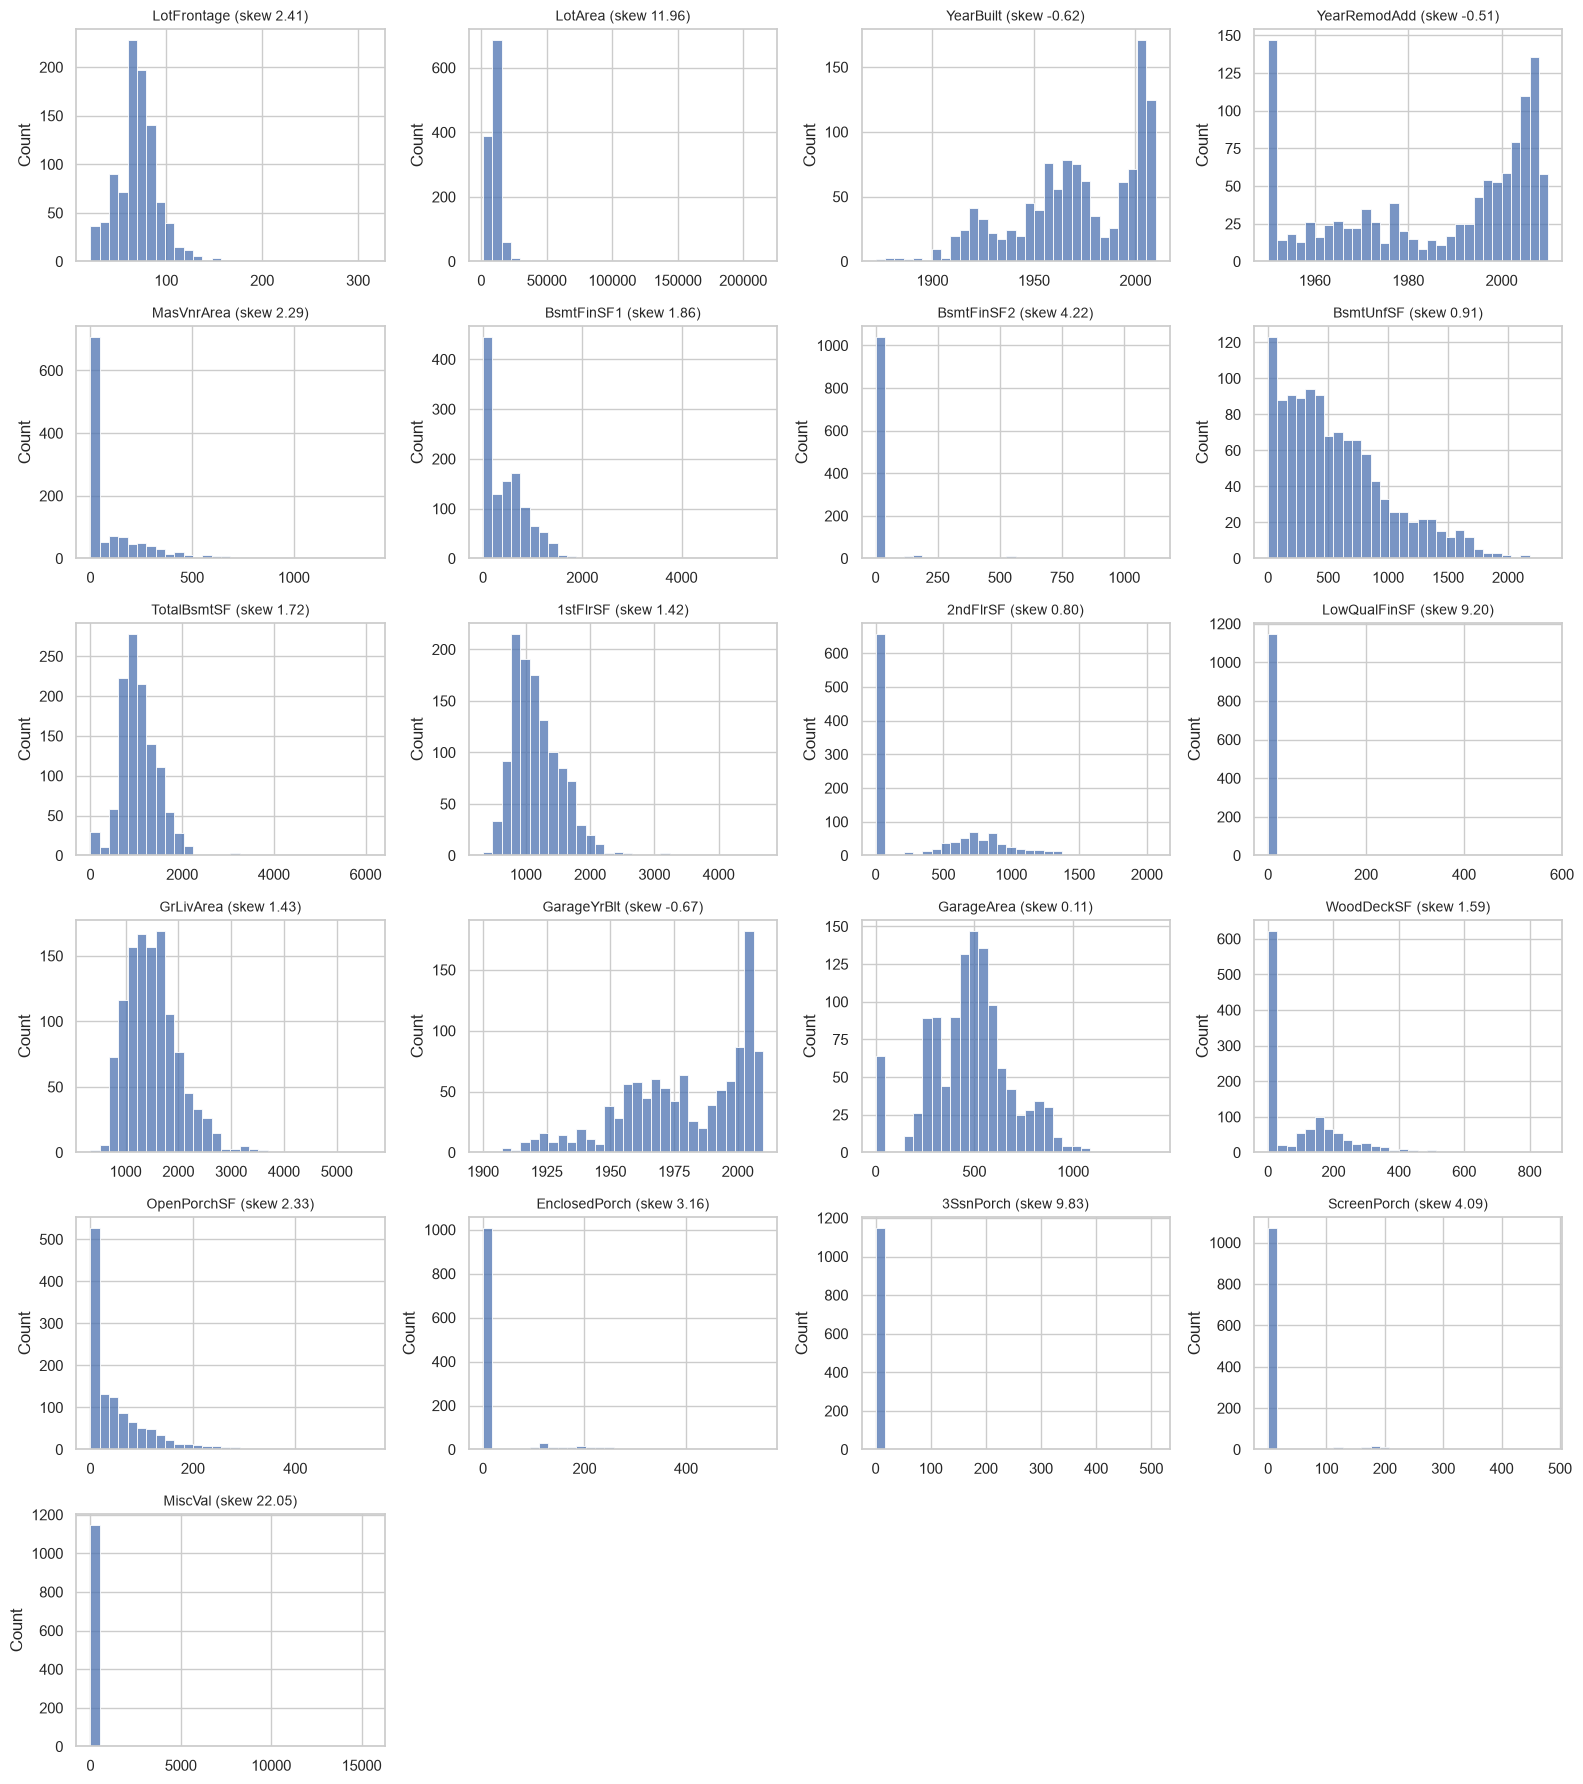

In [17]:
n = len(cont_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, col in zip(axes, cont_cols):
    sns.histplot(df[col].dropna(), bins=30, ax=ax)
    ax.set_title(f"{col} (skew {skew[col]:.2f})", fontsize=10)
    ax.set_xlabel("")
for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
save_fig("03_numeric_distributions")
plt.show()

### 5b · Correlation with the target
Top 10 numeric features by absolute correlation with `SalePrice` (expect `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF` near the top).

Top 10 correlations with SalePrice:
OverallQual     0.786
GrLivArea       0.696
GarageCars      0.641
GarageArea      0.624
TotalBsmtSF     0.598
1stFlrSF        0.588
FullBath        0.553
TotRmsAbvGrd    0.520
YearBuilt       0.517
YearRemodAdd    0.509
Saved figure -> reports\figures\04_correlation_heatmap.png


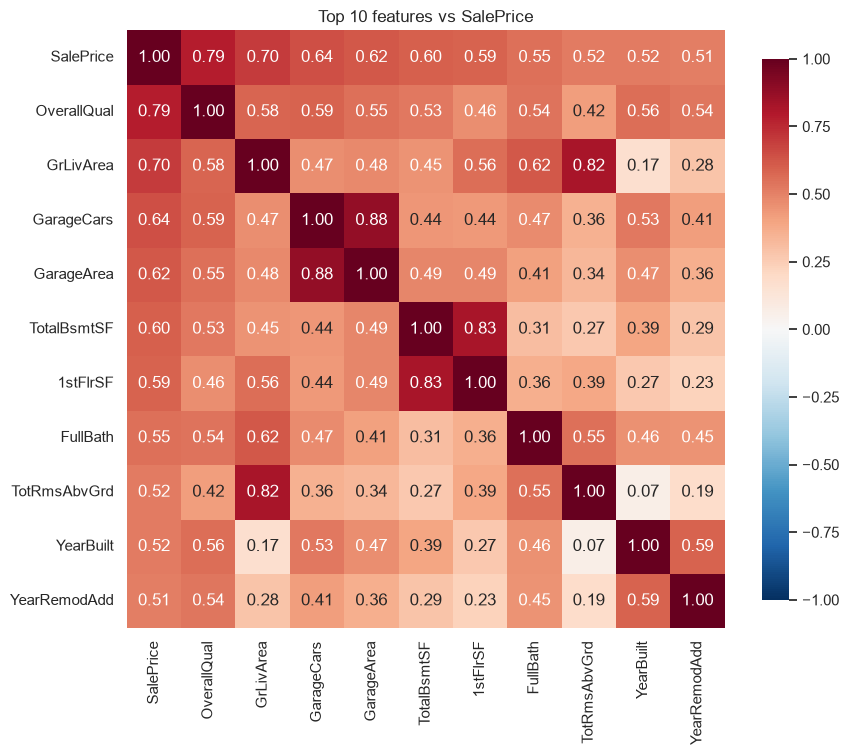

In [18]:
num_df = df.select_dtypes("number").drop(columns=nominal_forced, errors="ignore")
corr_target = (
    num_df.corr()[config.TARGET].drop(config.TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
)
top10 = corr_target.head(10)
print("Top 10 correlations with SalePrice:")
print(top10.round(3).to_string())

cols_top = [config.TARGET] + top10.index.tolist()
plt.figure(figsize=(9, 8))
sns.heatmap(
    num_df[cols_top].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8},
)
plt.title("Top 10 features vs SalePrice")
plt.tight_layout()
save_fig("04_correlation_heatmap")
plt.show()

### 5c · Multicollinearity
Pairs of features with absolute correlation above 0.8 carry nearly the same information. This destabilizes plain linear regression (inflated, unstable coefficients).

In [19]:
feat_corr = num_df.drop(columns=[config.TARGET]).corr().abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().reset_index()
pairs.columns = ["feature_a", "feature_b", "abs_corr"]
pairs = pairs[pairs["abs_corr"] > 0.8].sort_values("abs_corr", ascending=False).reset_index(drop=True)

pairs["corr_a_with_target"] = pairs["feature_a"].map(corr_target.abs()).round(3)
pairs["corr_b_with_target"] = pairs["feature_b"].map(corr_target.abs()).round(3)
pairs["suggested_drop"] = np.where(
    pairs["corr_a_with_target"] < pairs["corr_b_with_target"], pairs["feature_a"], pairs["feature_b"]
)
pairs["abs_corr"] = pairs["abs_corr"].round(3)
print(f"{len(pairs)} feature pairs with |corr| > 0.8")
pairs

4 feature pairs with |corr| > 0.8


,feature_a,feature_b,abs_corr,corr_a_with_target,corr_b_with_target,suggested_drop
0,GarageCars,GarageArea,0.883,0.641,0.624,GarageArea
1,TotalBsmtSF,1stFlrSF,0.827,0.598,0.588,1stFlrSF
2,GrLivArea,TotRmsAbvGrd,0.821,0.696,0.520,TotRmsAbvGrd
3,YearBuilt,GarageYrBlt,0.820,0.517,0.480,GarageYrBlt


In [20]:
pair_text = "; ".join(f"{a}/{b}" for a, b in zip(pairs["feature_a"], pairs["feature_b"])) or "none found"
log_decision(
    5,
    f"Skewed numeric columns: {len(skewed_cols)} of {len(cont_cols)} continuous columns have abs(skew) > 0.75",
    "Apply log1p (or PowerTransformer) to skewed continuous features inside the pipeline",
    "Phase 3 preprocessing",
)
log_decision(
    5,
    "Strongest numeric predictors: " + ", ".join(top10.index[:5]),
    "Keep all of them; use as sanity check for coefficients in Phase 5",
    "Phase 4 / Phase 5",
)
log_decision(
    5,
    f"Highly correlated feature pairs (abs(corr) > 0.8): {pair_text}",
    "Drop the member less correlated with the target, or combine them (e.g. TotalSF); "
    "use Ridge/Lasso to handle the rest",
    "Phase 3 feature selection / Phase 4 regularization",
)

### 5d · Categorical features
Cardinality, rare levels, and how price varies across categories (notably `Neighborhood`).

In [21]:
cat_cols = nominal_cols + [c for c in ordinal_cols if not is_num(df[c])]


def top_share(s: pd.Series) -> float:
    return s.value_counts(normalize=True).iloc[0] * 100 if s.notna().any() else np.nan


card = pd.DataFrame(
    {
        "n_levels": df[cat_cols].nunique(),
        "top_level": df[cat_cols].apply(lambda s: s.value_counts().index[0] if s.notna().any() else None),
        "top_level_share_%": df[cat_cols].apply(top_share).round(1),
        "rare_levels_<1%": df[cat_cols].apply(lambda s: int((s.value_counts(normalize=True) < 0.01).sum())),
    }
).sort_values("n_levels", ascending=False)

high_card = card.index[card["n_levels"] > 10].tolist()
print(f"{len(cat_cols)} categorical columns; high-cardinality (>10 levels): {high_card}")
card

45 categorical columns; high-cardinality (>10 levels): ['Neighborhood', 'Exterior2nd', 'MSSubClass', 'Exterior1st', 'MoSold']


,n_levels,top_level,top_level_share_%,rare_levels_<1%
Neighborhood,25,NAmes,15.5,4
Exterior2nd,16,VinylSd,35.1,6
MSSubClass,15,20,37.2,3
Exterior1st,15,VinylSd,36.0,5
MoSold,12,6,17.6,0
SaleType,9,WD,86.6,6
Condition1,9,Norm,86.0,4
HouseStyle,8,1Story,49.4,2
Condition2,8,Norm,99.1,7
RoofMatl,7,CompShg,98.4,6


Saved figure -> reports\figures\05_neighborhood_vs_price.png


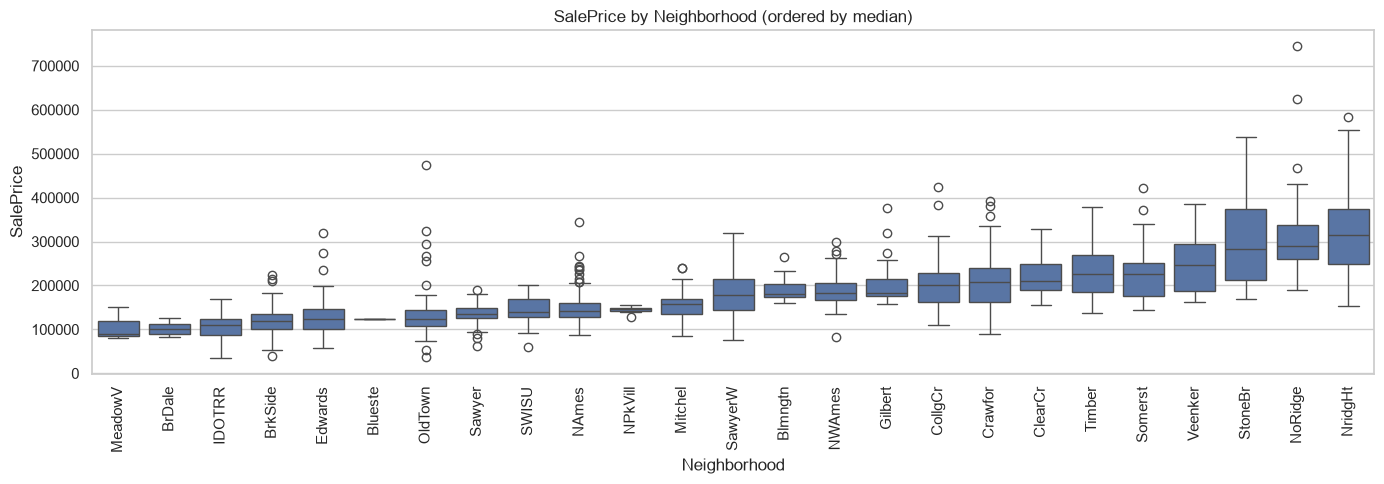

In [22]:
if "Neighborhood" in df.columns:
    order = df.groupby("Neighborhood")[config.TARGET].median().sort_values().index
    plt.figure(figsize=(14, 5))
    sns.boxplot(data=df, x="Neighborhood", y=config.TARGET, order=order)
    plt.xticks(rotation=90)
    plt.title("SalePrice by Neighborhood (ordered by median)")
    plt.tight_layout()
    save_fig("05_neighborhood_vs_price")
    plt.show()
else:
    print("Neighborhood not found in the data; skipping.")

Saved figure -> reports\figures\06_key_categoricals_vs_price.png


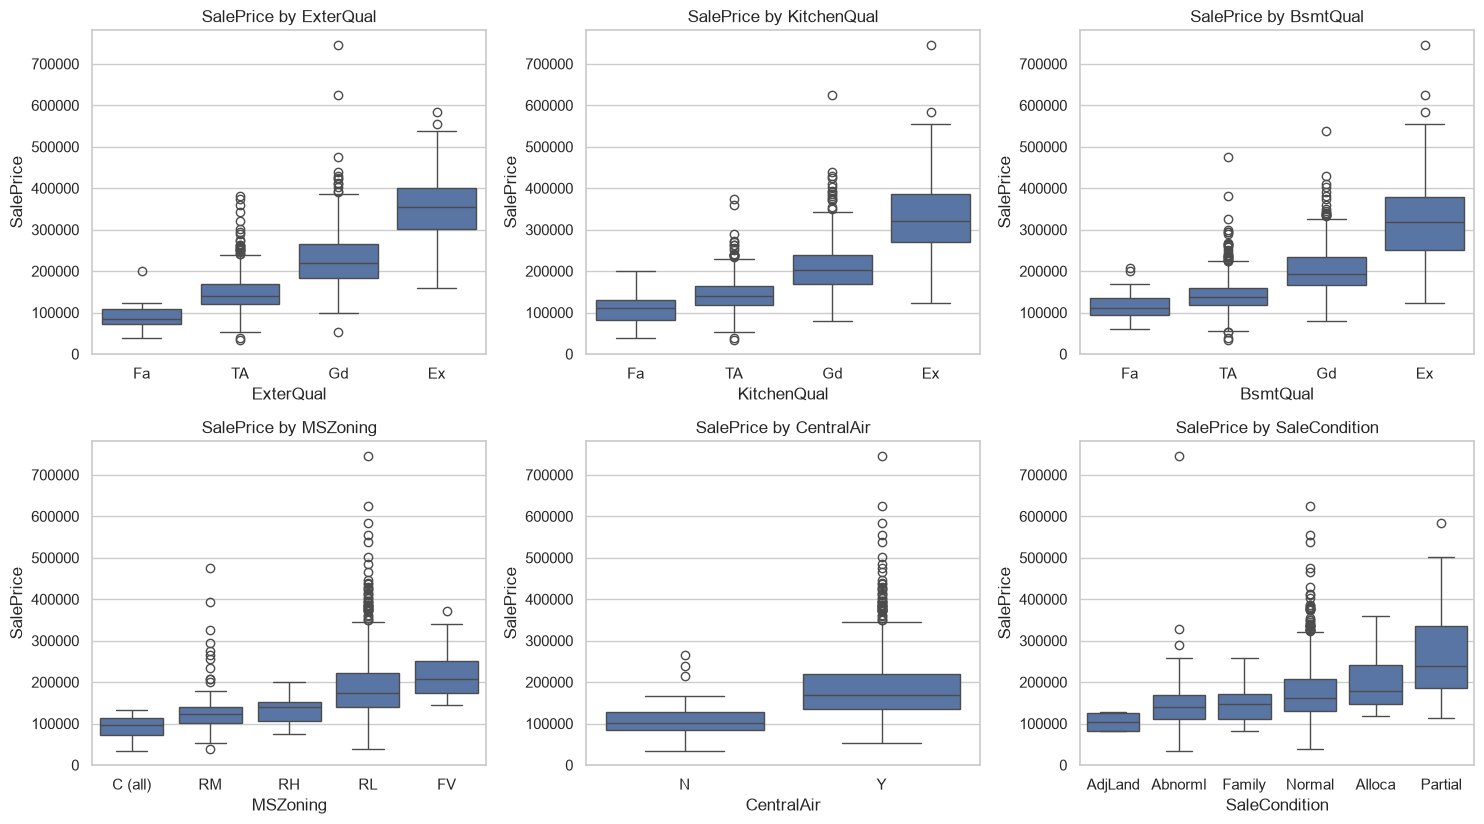

In [23]:
key_cats = [c for c in ["ExterQual", "KitchenQual", "BsmtQual", "MSZoning", "CentralAir", "SaleCondition"]
            if c in df.columns]
if key_cats:
    ncols = 3
    nrows = int(np.ceil(len(key_cats) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, key_cats):
        order = df.groupby(col)[config.TARGET].median().sort_values().index
        sns.boxplot(data=df, x=col, y=config.TARGET, order=order, ax=ax)
        ax.set_title(f"SalePrice by {col}")
    for ax in axes[len(key_cats):]:
        ax.set_visible(False)
    plt.tight_layout()
    save_fig("06_key_categoricals_vs_price")
    plt.show()

In [24]:
total_rare = int(card["rare_levels_<1%"].sum())
log_decision(
    5,
    f"High-cardinality categoricals (>10 levels): {', '.join(high_card) or 'none'}; "
    f"{total_rare} levels across all categoricals each cover <1% of rows",
    "One-hot with handle_unknown='ignore'; group rare levels into 'Other' (min_frequency) "
    "or target-encode high-cardinality columns inside CV folds",
    "Phase 3 encoders",
)
log_decision(
    5,
    "Neighborhood and quality ratings (ExterQual, KitchenQual, BsmtQual) show clear price differences",
    "Keep them; ordinal-encode the ratings, one-hot Neighborhood",
    "Phase 3 encoders",
)

## Step 6 · Check outliers
Scatter `SalePrice` against `GrLivArea`, `TotalBsmtSF` and `LotArea`. A few very large houses that sold cheaply can badly distort a linear model.
The dataset's creator recommends removing houses above 4,000 sq ft of living area; we check whether that rule applies to our training split.

**Output:** an outlier rule and the exact rows it flags.

Rows flagged by the rule (GrLivArea > 4000 and SalePrice < 300,000): 2
Saved figure -> reports\figures\07_outliers.png


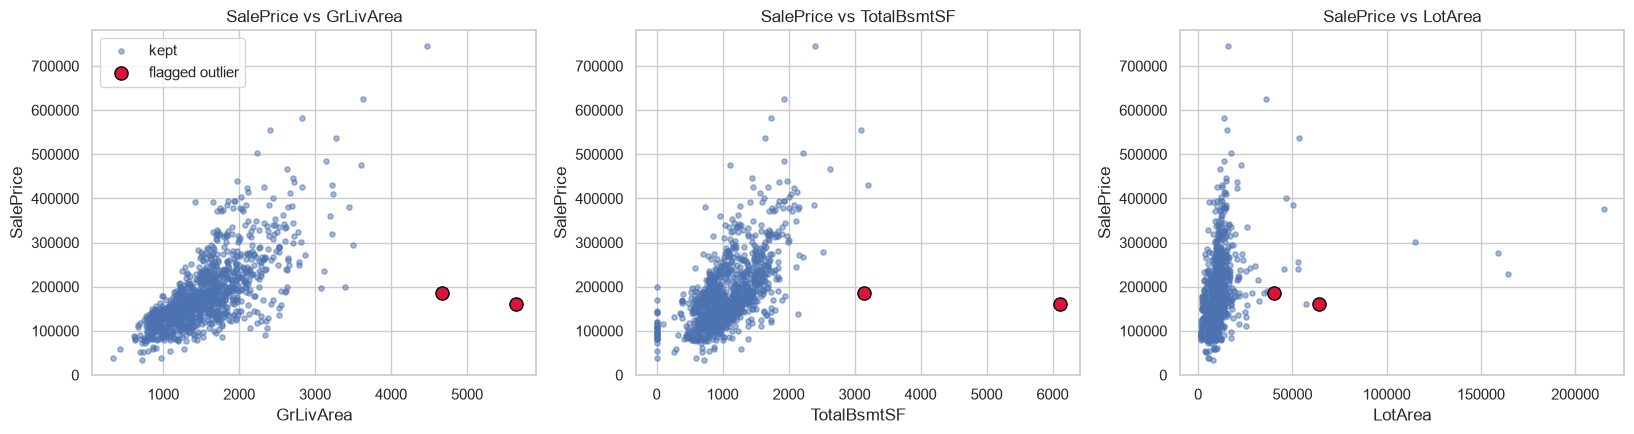

In [25]:
scatter_cols = [c for c in ["GrLivArea", "TotalBsmtSF", "LotArea"] if c in df.columns]


def outlier_rule(d: pd.DataFrame) -> pd.Series:
    """Very large living area but a low price: houses that break the size-price relationship."""
    return (d["GrLivArea"] > 4000) & (d[config.TARGET] < 300_000)


is_out = outlier_rule(df)
print(f"Rows flagged by the rule (GrLivArea > 4000 and SalePrice < 300,000): {int(is_out.sum())}")

fig, axes = plt.subplots(1, len(scatter_cols), figsize=(5.5 * len(scatter_cols), 4.5))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, scatter_cols):
    ax.scatter(df.loc[~is_out, col], df.loc[~is_out, config.TARGET], s=14, alpha=0.5, label="kept")
    ax.scatter(df.loc[is_out, col], df.loc[is_out, config.TARGET], s=90, color="crimson",
               edgecolor="black", label="flagged outlier")
    ax.set_xlabel(col)
    ax.set_ylabel(config.TARGET)
    ax.set_title(f"SalePrice vs {col}")
axes[0].legend()
plt.tight_layout()
save_fig("07_outliers")
plt.show()

In [26]:
show_cols = [c for c in ["GrLivArea", "TotalBsmtSF", "LotArea", "OverallQual", "Neighborhood",
                         "SaleCondition", config.TARGET] if c in df.columns]

print("Flagged rows:")
display(df.loc[is_out, show_cols])

print("\nFive largest houses by GrLivArea (for context):")
display(df.nlargest(5, "GrLivArea")[show_cols])

out_path = REPORTS_DIR / "outliers.csv"
df.loc[is_out].rename_axis("row_index_in_train_csv").to_csv(out_path)
print(f"\nSaved flagged rows -> {out_path.relative_to(config.PROJECT_ROOT)}")

Flagged rows:


,GrLivArea,TotalBsmtSF,LotArea,OverallQual,Neighborhood,SaleCondition,SalePrice
365,4676,3138,40094,10,Edwards,Partial,184750
495,5642,6110,63887,10,Edwards,Partial,160000



Five largest houses by GrLivArea (for context):


,GrLivArea,TotalBsmtSF,LotArea,OverallQual,Neighborhood,SaleCondition,SalePrice
495,5642,6110,63887,10,Edwards,Partial,160000
365,4676,3138,40094,10,Edwards,Partial,184750
173,4476,2396,15623,10,NoRidge,Abnorml,745000
539,3627,1930,35760,10,NoRidge,Normal,625000
638,3608,1107,22950,10,OldTown,Normal,475000



Saved flagged rows -> reports\outliers.csv


In [27]:
iqr_rows = []
for col in scatter_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    iqr_rows.append({"column": col, "upper_fence_(Q3+1.5*IQR)": round(fence, 1),
                     "n_above_fence": int((df[col] > fence).sum())})
print("Context: how many values sit beyond the usual IQR fence")
display(pd.DataFrame(iqr_rows))

if "LotArea" in df.columns:
    huge_lots = df[df["LotArea"] > 100_000]
    print(f"\nHouses with LotArea > 100,000 sq ft: {len(huge_lots)}")
    if len(huge_lots):
        display(huge_lots[[c for c in ["LotArea", "GrLivArea", config.TARGET] if c in df.columns]])

Context: how many values sit beyond the usual IQR fence


,column,upper_fence_(Q3+1.5*IQR),n_above_fence
0,GrLivArea,2761.4,23
1,TotalBsmtSF,2054.1,19
2,LotArea,17869.1,53



Houses with LotArea > 100,000 sq ft: 4


,LotArea,GrLivArea,SalePrice
407,115149,1824,302000
436,159000,2144,277000
748,164660,1786,228950
817,215245,2036,375000


In [28]:
n_out = int(is_out.sum())
log_decision(
    6,
    f"{n_out} house(s) have GrLivArea > 4000 sq ft but SalePrice < 300,000 "
    "(they break the size-price relationship; see reports/outliers.csv)",
    "Drop these rows from the TRAINING data only (never from the test set), "
    "using the same rule in code, before cross-validation",
    "Phase 3 data cleaning",
)
log_decision(
    6,
    "Very large lots (LotArea > 100,000) and big basements are rare but not clearly mispriced",
    "Do not drop; reduce their leverage with log1p on skewed areas and regularization",
    "Phase 3 / Phase 4",
)

## Step 7 · Write the decision log
Every finding becomes a row in `docs/eda_decisions.md`. Phase 3 is built from this file.
A few feature-engineering decisions are added here, based on the overlapping area, bath and year columns seen above.

In [29]:
log_decision(
    7,
    "Area, bathroom and year columns overlap (basement + floors, full + half baths, build/remodel years)",
    "Engineer TotalSF (TotalBsmtSF + 1stFlrSF + 2ndFlrSF), TotalBathrooms (full + 0.5*half, incl. basement), "
    "HouseAge (YrSold - YearBuilt), YearsSinceRemodel (YrSold - YearRemodAdd), "
    "and Has* flags (HasPool, HasGarage, HasFireplace, HasBasement)",
    "Phase 3 features.py (custom transformer)",
)
log_decision(
    7,
    "Preprocessing statistics must not leak from validation/test data",
    "Fit every imputer, scaler and encoder inside a scikit-learn Pipeline on training folds only",
    "Phase 3 pipeline.py",
)

decision_df = pd.DataFrame(sorted(DECISIONS, key=lambda d: d["step"]))
decision_df.insert(0, "#", range(1, len(decision_df) + 1))
pd.set_option("display.max_colwidth", 120)
decision_df

,#,step,finding,decision,applied_in
0,1,1,"1,168 training rows x 79 features; 0 duplicate rows",No duplicate handling needed,Phase 3 data cleaning
1,2,2,"2 numerically-coded categories (MSSubClass, MoSold); 22 ordered columns (quality/condition ratings etc.)",Cast MSSubClass and MoSold to category; ordinal-encode ordered columns (e.g. Po<Fa<TA<Gd<Ex); one-hot encode nominal...,Phase 3 ColumnTransformer
2,3,3,SalePrice is right-skewed (skew 1.74); after log1p skew is 0.12 and the Q-Q plot is much closer to a straight line,Train on log1p(SalePrice) and invert with expm1 for predictions; report RMSE on the log scale plus MAE and R2 on the...,Phase 3 pipeline (TransformedTargetRegressor) and Phase 5 evaluation
3,4,4,"14 columns have NA meaning 'feature absent' (e.g. PoolQC, GarageType, BsmtQual); NA matches the related size/count c...",Fill these with the 'None' category (not the mode); fill MasVnrArea with 0,Phase 3 imputers
4,5,4,LotFrontage and Electrical are genuinely missing values,LotFrontage: median by Neighborhood; Electrical: mode,Phase 3 imputers (fit on training folds only)
5,6,4,"Columns missing in more than 90% of rows: PoolQC, MiscFeature, Alley",Replace with a binary Has_<feature> flag (or drop); compare both in Phase 4,Phase 3 feature engineering
6,7,5,Skewed numeric columns: 17 of 21 continuous columns have abs(skew) > 0.75,Apply log1p (or PowerTransformer) to skewed continuous features inside the pipeline,Phase 3 preprocessing
7,8,5,"Strongest numeric predictors: OverallQual, GrLivArea, GarageCars, GarageArea, TotalBsmtSF",Keep all of them; use as sanity check for coefficients in Phase 5,Phase 4 / Phase 5
8,9,5,Highly correlated feature pairs (abs(corr) > 0.8): GarageCars/GarageArea; TotalBsmtSF/1stFlrSF; GrLivArea/TotRmsAbvG...,"Drop the member less correlated with the target, or combine them (e.g. TotalSF); use Ridge/Lasso to handle the rest",Phase 3 feature selection / Phase 4 regularization
9,10,5,"High-cardinality categoricals (>10 levels): Neighborhood, Exterior2nd, MSSubClass, Exterior1st, MoSold; 78 levels ac...",One-hot with handle_unknown='ignore'; group rare levels into 'Other' (min_frequency) or target-encode high-cardinali...,Phase 3 encoders


In [30]:
def esc(text) -> str:
    return str(text).replace("|", "/").replace("\n", " ")


decisions_path = DOCS_DIR / "eda_decisions.md"
lines = [
    "# EDA decisions (Phase 1)",
    "",
    f"_Generated by `notebooks/01_eda.ipynb` on {dt.date.today().isoformat()}. "
    f"Training split only ({len(df):,} rows)._",
    "",
    "| # | Step | Finding | Decision | Applied in |",
    "|---|---|---|---|---|",
]
for i, d in enumerate(sorted(DECISIONS, key=lambda d: d["step"]), start=1):
    lines.append(
        f"| {i} | {d['step']} | {esc(d['finding'])} | {esc(d['decision'])} | {esc(d['applied_in'])} |"
    )

decisions_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"Wrote {len(DECISIONS)} decisions -> {decisions_path.relative_to(config.PROJECT_ROOT)}")

Wrote 15 decisions -> docs\eda_decisions.md


## Definition of done
Run this last cell. All lines should say PASS.

In [31]:
figures = sorted(config.FIGURES_DIR.glob("*.png"))
checks = {
    "Only the training split was loaded (test split never opened)": LOADED_FILES == ["train.csv"],
    "At least 4 figures saved in reports/figures/": len(figures) >= 4,
    "Column-type table saved (Step 2)": (REPORTS_DIR / "column_types.csv").exists(),
    "Missing-value strategy saved (Step 4)": (REPORTS_DIR / "missing_value_strategy.csv").exists(),
    "Outlier rows saved (Step 6)": (REPORTS_DIR / "outliers.csv").exists(),
    "Every step 1-7 has at least one logged decision": {d["step"] for d in DECISIONS} >= set(range(1, 8)),
    "docs/eda_decisions.md written": decisions_path.exists() and decisions_path.stat().st_size > 0,
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\n{len(figures)} figures:")
for f in figures:
    print("  -", f.name)
print("\nPhase 1 complete." if all(checks.values()) else "\nSomething is missing - re-run the notebook top to bottom.")

PASS  Only the training split was loaded (test split never opened)
PASS  At least 4 figures saved in reports/figures/
PASS  Column-type table saved (Step 2)
PASS  Missing-value strategy saved (Step 4)
PASS  Outlier rows saved (Step 6)
PASS  Every step 1-7 has at least one logged decision
PASS  docs/eda_decisions.md written

7 figures:
  - 01_target_distribution.png
  - 02_missing_values.png
  - 03_numeric_distributions.png
  - 04_correlation_heatmap.png
  - 05_neighborhood_vs_price.png
  - 06_key_categoricals_vs_price.png
  - 07_outliers.png

Phase 1 complete.


## Next: Phase 2 (Baseline)
Using the decisions above: build the `DummyRegressor` and a minimal `LinearRegression` baseline, evaluated with 5-fold CV on the training data.